In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import joblib

pd.set_option('display.float_format', '{:.0f}'.format)

In [2]:
### Read CSV File
class AppendClosingQuote:
    def __init__(self, source):
        self.source = source
        self.appended = False

    def read(self, size=-1):
        content = self.source.read(size)
        if content == "" and not self.appended:
            self.appended = True
            return '"'
        return content

with open('vehicles.csv', encoding='utf-8', newline='') as csv_file:
    df = pd.read_csv(AppendClosingQuote(csv_file), index_col='id')

### Drop Extra Col
df = df.drop(columns=['url', 'region_url', 'image_url', 'description', 'VIN',
                      'posting_date', 'county', 'size', 'region'])
print('model' in df.columns)  

True


In [3]:
### Fill Numaric Col with Median
for col in ['year', 'odometer', 'lat', 'long']:
    df[col] = df[col].fillna(df[col].median())

### Fill cat col
cat_cols = ['manufacturer', 'model', 'condition', 'cylinders', 'fuel', 'title_status',
            'transmission', 'drive', 'type', 'paint_color', 'state']
for col in cat_cols:
    df[col] = df[col].fillna('unknown')

In [4]:
print(df.info())

<class 'pandas.DataFrame'>
Index: 161009 entries, 7222695916 to 7314264609
Data columns (total 16 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   price         161009 non-null  int64  
 1   year          161009 non-null  float64
 2   manufacturer  161009 non-null  str    
 3   model         161009 non-null  str    
 4   condition     161009 non-null  str    
 5   cylinders     161009 non-null  str    
 6   fuel          161009 non-null  str    
 7   odometer      161009 non-null  float64
 8   title_status  161009 non-null  str    
 9   transmission  161009 non-null  str    
 10  drive         161009 non-null  str    
 11  type          161009 non-null  str    
 12  paint_color   161009 non-null  str    
 13  state         161009 non-null  str    
 14  lat           161009 non-null  float64
 15  long          161009 non-null  float64
dtypes: float64(4), int64(1), str(11)
memory usage: 20.9 MB
None


In [5]:
### Remove outliers

## For Price
df = df[(df['price'] > 1000) & (df['price'] < 60000)]
print("Price:", df['price'].min(), "to", df['price'].max())

## For Odometer
df = df[(df['odometer'] > 1000) & (df['odometer'] < 300000)]
print("Odometer:", df['odometer'].min(), "to", df['odometer'].max())

## For Year
df = df[(df['year'] > 1995) & (df['year'] <= 2022)]
print("Year:", df['year'].min(), "to", df['year'].max())

print("Rows left:", df.shape[0])

Price: 1006 to 59999
Odometer: 1003.0 to 299999.0
Year: 1996.0 to 2022.0
Rows left: 131529


In [6]:
### add col car age and drop col year
df['car_age'] = 2026 - df['year']
df['car_age_sq'] = df['car_age'] ** 2
df['miles_per_year'] = df['odometer'] / (df['car_age'] + 1)
df['log_odometer'] = np.log1p(df['odometer'])
df = df.drop(columns=['year'])


In [7]:
### Top MOdels
top_models = df['model'].value_counts().head(30).index
df['model'] = df['model'].where(df['model'].isin(top_models), 'other')
print('model' in df.columns) 

True


In [8]:
### The fuel col into each category becomes its own column in Yes or No 
df = pd.get_dummies(df, columns=cat_cols, drop_first=True)
print(df.shape)

(131529, 155)


In [9]:
### Hides some data from the model so you can test it fairly
X = df.drop(columns=['price'])
y = df['price']

## No random_state: you shuffle differently each time.
## random_state=42: you shuffle in exactly the same way every time.
    
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [10]:
### Standard Scaler
num_cols = ['odometer', 'lat', 'long', 'car_age', 'car_age_sq', 'miles_per_year', 'log_odometer']
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

In [11]:
### Linear Regression
lr = LinearRegression()
lr.fit(X_train, np.log1p(y_train))

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](154,)","[-0.35, 0.04,-0.03,...,-1.53,-0.11, 0.38]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](154,)","['odometer','lat','long',...,'state_pa','state_unknown','state_wa']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,10.73
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,154
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(153)


In [12]:
### Predict and evaluate
y_pred = np.expm1(lr.predict(X_test))

print("MAE :", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2  :", r2_score(y_test, y_pred))

y_train_pred = np.expm1(lr.predict(X_train))
print("Train R2:", r2_score(y_train, y_train_pred))
print("Test R2 :", r2_score(y_test, y_pred))

MAE : 4386.848773860565
RMSE: 6674.873518558539
R2  : 0.7169208133925997
Train R2: 0.7184631597786166
Test R2 : 0.7169208133925997


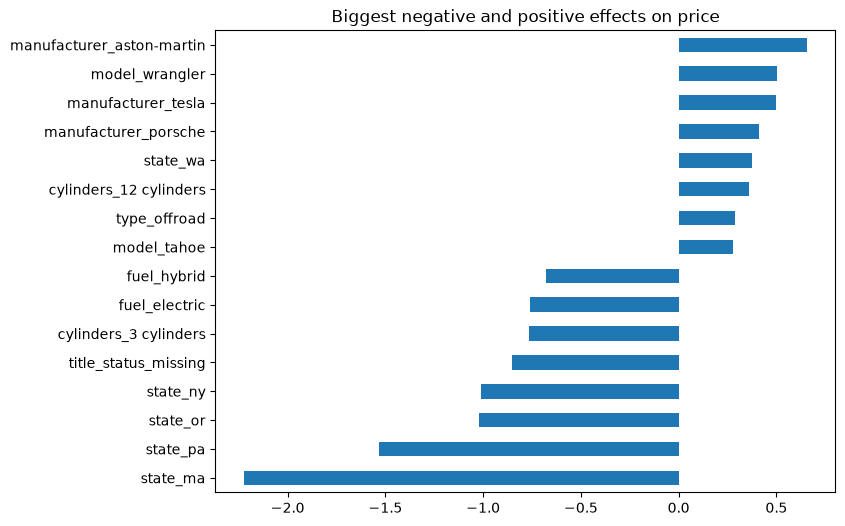

In [13]:
### Plot the coefficients
coef = pd.Series(lr.coef_, index=X.columns).sort_values()
pd.concat([coef.head(8), coef.tail(8)]).plot(kind='barh', figsize=(8, 6))
plt.title('Biggest negative and positive effects on price')
plt.show()

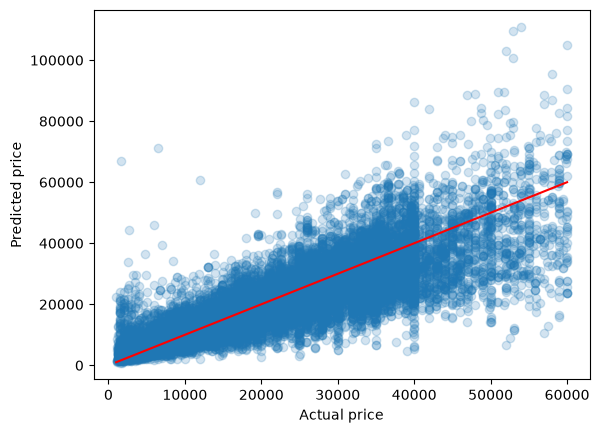

In [14]:
### Actual vs predicted plot
plt.scatter(y_test, y_pred, alpha=0.2)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red')
plt.xlabel('Actual price')
plt.ylabel('Predicted price')
plt.show()

In [15]:
### Check score
score = r2_score(y_test, y_pred)
print("Model score (R2):", round(score, 4))
print("In percent      :", round(score * 100, 1), "%")

Model score (R2): 0.7169
In percent      : 71.7 %


In [16]:
print(lr.score(X_test, y_test))

-2.302271387966213


In [17]:
print("Score (log scale):", lr.score(X_test, np.log1p(y_test)))

Score (log scale): 0.7775937052270594


In [18]:
print("Train score:", round(r2_score(y_train, np.expm1(lr.predict(X_train))), 4))
print("Test score :", round(r2_score(y_test, y_pred), 4))

Train score: 0.7185
Test score : 0.7169


In [19]:
### Check all score with R2 score
print("MAE       :", round(mean_absolute_error(y_test, y_pred), 2))
print("RMSE      :", round(np.sqrt(mean_squared_error(y_test, y_pred)), 2))
print("R2 score  :", round(r2_score(y_test, y_pred), 4))

MAE       : 4386.85
RMSE      : 6674.87
R2 score  : 0.7169


In [20]:
### Save the model
joblib.dump({
    'model': lr,
    'scaler': scaler,
    'columns': list(X.columns),
    'top_models': list(top_models),
    'num_cols': num_cols,
}, 'car_price_model.pkl')
print("Saved")

Saved


In [21]:
### Predict new car price 
def predict_price(car):
    row = pd.DataFrame([car])
    row['car_age'] = 2026 - row['year']
    row['car_age_sq'] = row['car_age'] ** 2
    row['miles_per_year'] = row['odometer'] / (row['car_age'] + 1)
    row['log_odometer'] = np.log1p(row['odometer'])
    row = row.drop(columns=['year'])
    row['model'] = row['model'].where(row['model'].isin(top_models), 'other')
    row = pd.get_dummies(row)
    row = row.reindex(columns=X.columns, fill_value=0)   # match training columns
    row[num_cols] = scaler.transform(row[num_cols])
    return np.expm1(lr.predict(row)[0])

new_car = {
    'year': 2015, 'odometer': 90000, 'lat': 34.0, 'long': -118.0,
    'manufacturer': 'toyota', 'model': 'corolla', 'condition': 'good',
    'cylinders': '4 cylinders', 'fuel': 'gas', 'title_status': 'clean',
    'transmission': 'automatic', 'drive': 'fwd', 'type': 'sedan',
    'paint_color': 'white', 'state': 'ca',
}
print("Predicted price:", round(predict_price(new_car)))

Predicted price: 9150


In [22]:
### Saved again value in saved fun
saved = joblib.load('car_price_model.pkl')
lr = saved['model']
scaler = saved['scaler']